# Indonesian Data Job Market Intelligence
## Pipeline Transformasi, Pembersihan Data, & Exploratory Data Analysis (EDA): Glints Indonesia

Notebook ini memproses data mentah lowongan kerja Glints Indonesia (Layer 8.1 Raw Data) hasil ekstraksi optimal menjadi dataset bersih terstandarisasi (Layer 8.2 Cleaned Jobs dan Layer 8.3 Job Skills), mengimplementasikan standarisasi kategorikal tingkat pengalaman (`experience_level`), menyelesaikan pemetaan lokasi hierarkis via breadcrumb, serta menjawab pertanyaan bisnis utama (BR-01 s/d BR-06).

### Sel 1: Inisialisasi Dependensi & Library Analisis Data

Memuat pustaka standar analisis data (`pandas`, `numpy`), visualisasi data (`matplotlib`, `seaborn`), modul regex (`re`), serta menyiapkan direktori output untuk dataset terproses (`data/processed/`) dan figur grafis (`outputs/figures/`).

In [1]:
import os
import sys
import re
import glob
from pathlib import Path
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Konsistensi encoding terminal Windows
if sys.platform == "win32" and hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 9

# Setup direktori proyek
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent if NOTEBOOK_DIR.name in ["transform_data", "extract_data", "load_data"] else NOTEBOOK_DIR
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUTS_DIR = PROJECT_ROOT / "outputs" / "figures"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

print("Pustaka berhasil dimuat.")
print(f"Direktori data mentah    : {RAW_DATA_DIR}")
print(f"Direktori data terproses : {PROCESSED_DATA_DIR}")

Pustaka berhasil dimuat.
Direktori data mentah    : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\raw
Direktori data terproses : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed


### Sel 2: Pemuatan Data Mentah Glints Terbaru

Membaca dataset mentah terbaru yang memuat hasil ekstraksi optimal (termasuk hierarki breadcrumb lokasi dan badge sistem).

In [2]:
raw_files = sorted(RAW_DATA_DIR.glob("glints_raw_*.csv"))
if not raw_files:
    raw_files = sorted(RAW_DATA_DIR.glob("glints_checkpoint_details.csv"))

if not raw_files:
    raise FileNotFoundError(f"Tidak ada file glints_raw_*.csv di {RAW_DATA_DIR}")

latest_raw_file = raw_files[-1]
print(f"Memuat data mentah: {latest_raw_file.name}")

df_raw = pd.read_csv(latest_raw_file)
print(f"Dimensi data mentah: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
display(df_raw.head(3))

Memuat data mentah: glints_raw_20261031_223844.csv
Dimensi data mentah: 319 baris, 16 kolom


,source,source_job_id,job_url,title_raw,company_raw,location_raw,salary_raw,job_type_raw,education_raw,experience_raw,posted_date_raw,description_raw,collected_at,parse_status,parse_error,search_keyword
0,glints,recommended,https://glints.com/id/opportunities/jobs/recom...,Pekerjaan yang direkomendasikan untuk kamu,SoftwareSeni,"Yogyakarta, DI Yogyakarta, Yogyakarta, DI Yogy...",NaN,NaN,NaN,NaN,NaN,Deskripsi pekerjaan Senior Backend Developer (...,2026-10-31T22:08:07.103080,OK,NaN,Data Analyst
1,glints,a0726783-7124-4916-8797-52a6bee58e07,https://glints.com/id/opportunities/jobs/data-...,Data Analyst,Nusantara Sakti Group,"Jawa Tengah, Semarang, Surabaya, Jawa Timur, S...",Rp 7.000.000 - 10.000.000 / Bulan,NaN,Minimal Sarjana (S1),1 - 3 tahun pengalaman,NaN,Deskripsi pekerjaan Data Analyst Nusantara Sak...,2026-10-31T22:08:13.320338,OK,NaN,Data Analyst
2,glints,07401ee8-bc95-483c-a0ba-ba1779d88770,https://glints.com/id/opportunities/jobs/data-...,Data Analyst,PT Sigma Digital Nusantara,"DI Yogyakarta, Yogyakarta, Kab. Sukoharjo, Jaw...",Perusahaan tidak menampilkan gaji,NaN,Minimal Sarjana (S1),1 - 3 tahun pengalaman,NaN,Deskripsi pekerjaan Data Analyst PT Sigma Digi...,2026-10-31T22:08:17.954025,OK,NaN,Data Analyst


### Sel 3: Audit Kualitas Data Mentah & Profil Nilai Tidak Disebutkan

Memeriksa kelengkapan awal atribut data mentah dan status parsing.

In [3]:
# 1. Pengecekan duplikasi
dup_urls = df_raw.duplicated(subset=['job_url']).sum()
print(f"Jumlah baris duplikat (job_url) : {dup_urls}")

# 2. Audit kelengkapan kolom mentah
missing_summary = pd.DataFrame({
    'Missing Count': df_raw.isnull().sum(),
    'Missing (%)': (df_raw.isnull().mean() * 100).round(2)
})
print("\nRingkasan Nilai Kosong Kolom Mentah:")
print(missing_summary)

Jumlah baris duplikat (job_url) : 0

Ringkasan Nilai Kosong Kolom Mentah:
                 Missing Count  Missing (%)
source                       0         0.00
source_job_id                0         0.00
job_url                      0         0.00
title_raw                    0         0.00
company_raw                  0         0.00
location_raw                 0         0.00
salary_raw                   1         0.31
job_type_raw               319       100.00
education_raw                1         0.31
experience_raw               7         2.19
posted_date_raw            319       100.00
description_raw              0         0.00
collected_at                 0         0.00
parse_status                 0         0.00
parse_error                319       100.00
search_keyword               0         0.00


### Sel 4: Rekayasa Fitur 1 – Normalisasi Lokasi Presisi (Provinsi & Kota)

Mengekstrak dan menstandardisasi lokasi penempatan kerja menjadi entitas kota dan provinsi baku tingkat nasional, serta membersihkan duplikasi hierarki breadcrumb yang berulang.

In [4]:
df_clean = df_raw.copy()

PROVINCE_MAP = {
    'dki jakarta': 'DKI Jakarta',
    'jakarta': 'DKI Jakarta',
    'di yogyakarta': 'DI Yogyakarta',
    'd.i. yogyakarta': 'DI Yogyakarta',
    'daerah istimewa yogyakarta': 'DI Yogyakarta',
    'yogyakarta': 'DI Yogyakarta',
    'jawa barat': 'Jawa Barat',
    'jawa timur': 'Jawa Timur',
    'jawa tengah': 'Jawa Tengah',
    'banten': 'Banten',
    'bali': 'Bali',
    'sumatera utara': 'Sumatera Utara',
    'sumatera barat': 'Sumatera Barat',
    'sumatera selatan': 'Sumatera Selatan',
    'kepulauan riau': 'Kepulauan Riau',
    'riau': 'Riau',
    'lampung': 'Lampung',
    'sulawesi selatan': 'Sulawesi Selatan',
    'sulawesi utara': 'Sulawesi Utara',
    'kalimantan timur': 'Kalimantan Timur',
    'kalimantan selatan': 'Kalimantan Selatan',
    'kalimantan barat': 'Kalimantan Barat',
    'nusa tenggara barat': 'Nusa Tenggara Barat',
    'nusa tenggara timur': 'Nusa Tenggara Timur',
    'papua': 'Papua',
    'aceh': 'Aceh'
}

CITY_TO_PROVINCE = {
    # DKI Jakarta
    'jakarta selatan': 'DKI Jakarta', 'jakarta pusat': 'DKI Jakarta', 'jakarta barat': 'DKI Jakarta',
    'jakarta timur': 'DKI Jakarta', 'jakarta utara': 'DKI Jakarta', 'jakarta': 'DKI Jakarta',
    # Banten
    'tangerang': 'Banten', 'tangerang selatan': 'Banten', 'kab. tangerang': 'Banten',
    'kabupaten tangerang': 'Banten', 'serang': 'Banten', 'cilegon': 'Banten',
    # Jawa Barat
    'bandung': 'Jawa Barat', 'kota bandung': 'Jawa Barat', 'kab. bandung': 'Jawa Barat',
    'bandung barat': 'Jawa Barat', 'bekasi': 'Jawa Barat', 'kota bekasi': 'Jawa Barat',
    'kab. bekasi': 'Jawa Barat', 'depok': 'Jawa Barat', 'bogor': 'Jawa Barat',
    'kota bogor': 'Jawa Barat', 'kab. bogor': 'Jawa Barat', 'cirebon': 'Jawa Barat',
    'sukabumi': 'Jawa Barat', 'karawang': 'Jawa Barat', 'kab. karawang': 'Jawa Barat',
    'cimahi': 'Jawa Barat',
    # Jawa Timur
    'surabaya': 'Jawa Timur', 'kota surabaya': 'Jawa Timur', 'malang': 'Jawa Timur',
    'kota malang': 'Jawa Timur', 'kab. malang': 'Jawa Timur', 'sidoarjo': 'Jawa Timur',
    'kab. sidoarjo': 'Jawa Timur', 'gresik': 'Jawa Timur', 'kab. gresik': 'Jawa Timur',
    'pasuruan': 'Jawa Timur', 'madiun': 'Jawa Timur', 'kab. madiun': 'Jawa Timur',
    'kediri': 'Jawa Timur', 'jember': 'Jawa Timur', 'banyuwangi': 'Jawa Timur',
    # Jawa Tengah
    'semarang': 'Jawa Tengah', 'kota semarang': 'Jawa Tengah', 'surakarta': 'Jawa Tengah',
    'solo': 'Jawa Tengah', 'salatiga': 'Jawa Tengah', 'magelang': 'Jawa Tengah',
    'sukoharjo': 'Jawa Tengah', 'kab. sukoharjo': 'Jawa Tengah', 'banyumas': 'Jawa Tengah',
    'purwokerto': 'Jawa Tengah', 'kudus': 'Jawa Tengah', 'klaten': 'Jawa Tengah',
    # DI Yogyakarta
    'yogyakarta': 'DI Yogyakarta', 'kota yogyakarta': 'DI Yogyakarta', 'sleman': 'DI Yogyakarta',
    'kab. sleman': 'DI Yogyakarta', 'bantul': 'DI Yogyakarta', 'kulon progo': 'DI Yogyakarta',
    'gunungkidul': 'DI Yogyakarta',
    # Luar Jawa
    'denpasar': 'Bali', 'badung': 'Bali', 'gianyar': 'Bali',
    'medan': 'Sumatera Utara', 'kota medan': 'Sumatera Utara', 'deli serdang': 'Sumatera Utara',
    'batam': 'Kepulauan Riau', 'kota batam': 'Kepulauan Riau',
    'makassar': 'Sulawesi Selatan', 'kota makassar': 'Sulawesi Selatan',
    'palembang': 'Sumatera Selatan', 'pekanbaru': 'Riau', 'bandar lampung': 'Lampung',
    'balikpapan': 'Kalimantan Timur', 'samarinda': 'Kalimantan Timur',
    'banjarmasin': 'Kalimantan Selatan', 'pontianak': 'Kalimantan Barat',
    'manado': 'Sulawesi Utara', 'mataram': 'Nusa Tenggara Barat', 'kupang': 'Nusa Tenggara Timur',
    'padang': 'Sumatera Barat'
}

def parse_glints_location(raw_loc: str) -> tuple[str, str]:
    if pd.isna(raw_loc) or not str(raw_loc).strip():
        return 'Tidak Disebutkan', 'Tidak Disebutkan'
    
    # Ambil elemen unik berurutan dari split koma
    raw_parts = [p.strip() for p in str(raw_loc).split(',') if p.strip()]
    unique_parts = []
    seen = set()
    for p in raw_parts:
        p_clean = re.sub(r"\s+", " ", p).strip()
        p_low = p_clean.lower()
        if p_low not in seen:
            seen.add(p_low)
            unique_parts.append(p_clean)
            
    found_city = None
    found_prov = None
    
    # 1. Cek dari 3 bagian unik pertama
    for part in unique_parts[:3]:
        p_low = part.lower()
        if p_low in CITY_TO_PROVINCE:
            found_city = part
            found_prov = CITY_TO_PROVINCE[p_low]
            break
        elif p_low in PROVINCE_MAP:
            found_prov = PROVINCE_MAP[p_low]
            
    # 2. Normalisasi nama kota
    if found_city:
        p_low = found_city.lower()
        if 'jakarta selatan' in p_low:
            found_city = 'Jakarta Selatan'
        elif 'jakarta pusat' in p_low:
            found_city = 'Jakarta Pusat'
        elif 'jakarta barat' in p_low:
            found_city = 'Jakarta Barat'
        elif 'jakarta timur' in p_low:
            found_city = 'Jakarta Timur'
        elif 'jakarta utara' in p_low:
            found_city = 'Jakarta Utara'
        elif p_low == 'jakarta':
            found_city = 'DKI Jakarta'
        elif 'tangerang selatan' in p_low:
            found_city = 'Tangerang Selatan'
        elif 'kab. tangerang' in p_low:
            found_city = 'Kab. Tangerang'
        elif 'tangerang' in p_low:
            found_city = 'Tangerang'
        elif 'surabaya' in p_low:
            found_city = 'Surabaya'
        elif 'bandung' in p_low:
            found_city = 'Bandung'
        elif 'semarang' in p_low:
            found_city = 'Semarang'
        elif 'yogyakarta' in p_low:
            found_city = 'Yogyakarta'
        elif 'sleman' in p_low:
            found_city = 'Sleman'
        elif 'malang' in p_low:
            found_city = 'Malang'
        else:
            found_city = found_city.title()
            
    # 3. Jika hanya provinsi yang ketemu, cari kandidat kota dari part lain
    if not found_city:
        for part in unique_parts:
            p_low = part.lower()
            if p_low not in PROVINCE_MAP and len(part) > 2:
                found_city = part.title()
                break
                
    city = found_city or 'Tidak Disebutkan'
    province = found_prov or 'Tidak Disebutkan'
    
    if province == 'Tidak Disebutkan' and city.lower() in CITY_TO_PROVINCE:
        province = CITY_TO_PROVINCE[city.lower()]
        
    return province, city

df_clean['province'], df_clean['city'] = zip(*df_clean['location_raw'].apply(parse_glints_location))

print("Distribusi Provinsi Hasil Normalisasi (Glints):")
print(df_clean['province'].value_counts())
print("\nDistribusi 10 Kota Teratas (Glints):")
print(df_clean['city'].value_counts().head(10))

Distribusi Provinsi Hasil Normalisasi (Glints):
province
DKI Jakarta            210
DI Yogyakarta           27
Banten                  23
Jawa Barat              17
Jawa Tengah             15
Jawa Timur              14
Bali                     3
Sulawesi Selatan         2
Tidak Disebutkan         2
Sulawesi Utara           2
Nusa Tenggara Timur      1
Riau                     1
Kepulauan Riau           1
Sumatera Utara           1
Name: count, dtype: int64

Distribusi 10 Kota Teratas (Glints):
city
Jakarta Selatan      97
Jakarta Barat        43
Jakarta Pusat        34
Jakarta Utara        28
Yogyakarta           16
Sleman               10
Tangerang             9
Bandung               9
Semarang              9
Tangerang Selatan     8
Name: count, dtype: int64


### Sel 5: Rekayasa Fitur 2 — Tipe Pekerjaan & Mode Kerja

Mendekomposisi nilai gabungan pada `job_type_raw` menjadi `employment_type` (*Full-time, Contract, Internship, Part-time*) dan `work_mode` (*On-site, Hybrid, Remote*).

In [5]:
def parse_job_type_and_mode(row):
    text = (str(row.get('job_type_raw', '')) + ' ' + str(row.get('description_raw', ''))).lower()
    
    # 1. Tipe Pekerjaan
    emp_type = 'Full-time'
    if 'magang' in text or 'internship' in text:
        emp_type = 'Internship'
    elif 'kontrak' in text or 'contract' in text:
        emp_type = 'Contract'
    elif 'paruh waktu' in text or 'part-time' in text:
        emp_type = 'Part-time'
        
    # 2. Mode Kerja
    work_mode = 'On-site'
    if 'remote' in text:
        work_mode = 'Remote'
    elif 'hybrid' in text or 'hibrida' in text:
        work_mode = 'Hybrid'
        
    return emp_type, work_mode

df_clean['employment_type'], df_clean['work_mode'] = zip(*df_clean.apply(parse_job_type_and_mode, axis=1))

print("Distribusi Tipe Pekerjaan:")
print(df_clean['employment_type'].value_counts())
print("\nDistribusi Mode Kerja:")
print(df_clean['work_mode'].value_counts())

Distribusi Tipe Pekerjaan:
employment_type
Full-time     281
Contract       19
Internship     18
Part-time       1
Name: count, dtype: int64

Distribusi Mode Kerja:
work_mode
On-site    300
Hybrid      10
Remote       9
Name: count, dtype: int64


### Sel 6: Rekayasa Fitur 3 — Normalisasi Informasi Gaji Multi-Format

Mengekstrak rentang gaji bulanan ke dalam nilai numerik bersih (`salary_min`, `salary_max`, `salary_median`) mendukung format singkatan juta (`Rp X,X-X,Xjt`) maupun format angka penuh (`Rp X.XXX.XXX - Y.YYY.YYY`).

In [6]:
def parse_salary(text):
    if pd.isna(text):
        return np.nan, np.nan, np.nan
    s = str(text)
    if 'tidak ditampilkan' in s.lower() or 'tidak menampilkan' in s.lower():
        return np.nan, np.nan, np.nan
        
    # Format 1: Rp 2,5-3,5jt atau Rp 5-5,5jt
    m_jt = re.search(r'Rp\s*([\d,\.]+)\s*-\s*([\d,\.]+)\s*jt', s, re.IGNORECASE)
    if m_jt:
        min_v = float(m_jt.group(1).replace(',', '.')) * 1_000_000
        max_v = float(m_jt.group(2).replace(',', '.')) * 1_000_000
        return min_v, max_v, (min_v + max_v) / 2
        
    # Format 2: Rp 8.000.000 - 10.000.000
    m_full = re.search(r'Rp\s*([\d\.]+)\s*-\s*([\d\.]+)', s)
    if m_full:
        min_v = float(m_full.group(1).replace('.', ''))
        max_v = float(m_full.group(2).replace('.', ''))
        return min_v, max_v, (min_v + max_v) / 2

    # Format 3: Nilai tunggal
    m_single = re.search(r'Rp\s*([\d\.]+)', s)
    if m_single:
        val = float(m_single.group(1).replace('.', ''))
        return val, val, val

    return np.nan, np.nan, np.nan

df_clean['salary_min'], df_clean['salary_max'], df_clean['salary_median'] = zip(*df_clean['salary_raw'].apply(parse_salary))

valid_salary = df_clean['salary_median'].notnull().sum()
print(f"Lowongan dengan gaji valid: {valid_salary} dari {len(df_clean)} ({valid_salary/len(df_clean)*100:.1f}%)")

Lowongan dengan gaji valid: 223 dari 319 (69.9%)


### Sel 7: Rekayasa Fitur 4 — Persyaratan Pendidikan Formal (Prioritas Badge Portal)

Mengekstrak kualifikasi pendidikan minimum dengan memprioritaskan badge resmi sistem portal (`education_raw`), kemudian menggunakan teks deskripsi sebagai *secondary fallback*.

In [7]:
def parse_education(row):
    edu_badge = str(row.get('education_raw', ''))
    if 'Sarjana' in edu_badge or 'S1' in edu_badge:
        return 'Sarjana (S1)'
    if 'Diploma' in edu_badge or 'D1' in edu_badge or 'D3' in edu_badge or 'D4' in edu_badge:
        return 'Diploma (D1-D4)'
    if 'SMA' in edu_badge or 'SMK' in edu_badge:
        return 'SMA/SMK'
    if 'Magister' in edu_badge or 'S2' in edu_badge:
        return 'Magister (S2)'
        
    # Fallback ke description_raw
    desc = str(row.get('description_raw', '')).lower()
    if any(k in desc for k in ['s2', 'magister', 'master']):
        return 'Magister (S2)'
    if any(k in desc for k in ['s1', 'sarjana', 'bachelor', 'undergraduate']):
        return 'Sarjana (S1)'
    if any(k in desc for k in ['d3', 'd4', 'diploma']):
        return 'Diploma (D1-D4)'
    if any(k in desc for k in ['sma', 'smk', 'high school']):
        return 'SMA/SMK'
        
    return 'Tidak Disebutkan'

df_clean['education_requirement'] = df_clean.apply(parse_education, axis=1)

print("Distribusi Persyaratan Pendidikan Formal:")
print(df_clean['education_requirement'].value_counts())

Distribusi Persyaratan Pendidikan Formal:
education_requirement
Sarjana (S1)        249
Diploma (D1-D4)      45
SMA/SMK              24
Tidak Disebutkan      1
Name: count, dtype: int64


### Sel 8: Rekayasa Fitur 5 — Tingkat Pengalaman Kategorikal (`experience_level`)

Menyederhanakan representasi pengalaman kerja dengan menggantikan kolom numerik/flag rentang (`experience_min_years`, `experience_max_years`, `is_entry_level`) menjadi satu variabel kategorikal standar industri:
- **Entry-Level**: Magang/Internship, Fresh Graduate, atau pengalaman $\le 1$ tahun.
- **Junior / Associate**: Pengalaman 1–3 tahun atau berstatus peran junior/associate.
- **Mid-Level**: Pengalaman 3–5 tahun.
- **Senior-Level**: Pengalaman $\ge 5$ tahun atau judul peran memuat Senior, Lead, Principal, Head.
- **Tidak Disebutkan**: Tidak mensyaratkan durasi masa kerja secara eksplisit.

In [8]:
def parse_experience_level(row):
    exp_badge = str(row.get('experience_raw', '')).lower()
    title = str(row.get('title_raw', '')).lower()
    emp = str(row.get('employment_type', '')).lower()
    desc = str(row.get('description_raw', '')).lower()
    
    # 1. Senior-Level
    if any(k in title for k in ['senior', 'sr.', 'lead', 'principal', 'head']):
        return 'Senior-Level'
    if '5 - 10' in exp_badge or '5+' in exp_badge or re.search(r'([5-9]|\d{2})\+?\s*(?:tahun|years?)', desc):
        return 'Senior-Level'
        
    # 2. Entry-Level
    if 'kurang dari 1 tahun' in exp_badge or emp == 'internship' or any(k in title for k in ['intern', 'magang', 'fresh graduate', 'trainee']):
        return 'Entry-Level'
    if any(k in desc for k in ['fresh graduate', 'freshgraduate', 'lulusan baru', 'tanpa pengalaman']):
        return 'Entry-Level'
        
    # 3. Junior / Associate (1 - 3 tahun)
    if '1 - 3 tahun' in exp_badge or any(k in title for k in ['junior', 'associate']):
        return 'Junior / Associate'
    if re.search(r'1\s*[-–]\s*[23]\s*tahun', desc):
        return 'Junior / Associate'
        
    # 4. Mid-Level (3 - 5 tahun)
    if '3 - 5 tahun' in exp_badge or re.search(r'[3-4]\s*[-–]\s*[4-5]\s*tahun', desc):
        return 'Mid-Level'
        
    return 'Tidak Disebutkan'

df_clean['experience_level'] = df_clean.apply(parse_experience_level, axis=1)

print("Distribusi Tingkat Pengalaman Kategorikal (experience_level):")
print(df_clean['experience_level'].value_counts())

Distribusi Tingkat Pengalaman Kategorikal (experience_level):
experience_level
Junior / Associate    135
Mid-Level              62
Senior-Level           61
Entry-Level            60
Tidak Disebutkan        1
Name: count, dtype: int64


### Sel 9: Rekayasa Fitur 6 – Taksonomi Profesi Data, Filter Non-Data & Klasifikasi Industri

Mengklasifikasikan lowongan ke dalam 4 taksonomi data standar, menyaring peran non-teknis data (seperti Business Development, HRBP, dsb.), serta menetapkan klasifikasi sektor industri baku (`industry_category`).

In [9]:
def classify_role(title):
    t = str(title).lower().strip()

    # 1. Peran non-data yang harus disaring
    excluded_keywords = [
        'business development',
        'business support',
        'business assistant',
        'business consultant',
        'hrbp',
        'human resources',
        'creative digital',
        'data entry',
        'fullstack developer',
        'solution architect',
        'new business',
        'project manager',
        'teknisi',
        'hardware engineer',
        'sales engineer',
        'software quality engineer',
        'qa engineer',
        'java developer',
        'it developer',
        'perbaikan printer',
        'operator',
        'data center',
        'facility engineer',
        'network engineer',
    ]

    if any(kw in t for kw in excluded_keywords):
        return 'Excluded: Non-Data', 'Excluded'

    # 2. Machine Learning & AI
    if any(kw in t for kw in [
        'machine learning',
        'ml engineer',
        'ml developer',
        'mlops',
        'ai engineer',
        'ai researcher',
        'ai specialist',
        'ai spesialist',
        'artificial intelligence',
        'programmer ai',
        'ai / ml',
        'ai/ml',
        'deep learning',
        'computer vision',
        'nlp engineer',
        'natural language processing',
        'pengembang machine learning',
        'insinyur pembelajaran mesin',
        'ilmuwan kecerdasan buatan',
    ]):
        return 'Machine Learning & AI', 'Machine Learning / AI Engineer'

    # 3. Data Engineering
    if any(kw in t for kw in [
        'data engineer',
        'data engineering',
        'big data',
        'etl developer',
        'etl engineer',
        'etl',
        'talend',
        'analytics engineer',
        'database administrator',
        'database engineer',
        'database developer',
        'dba',
        'data architect',
        'data platform',
        'data warehouse',
        'data pipeline',
        'data modeler',
        'data modeller',
        'data integration',
        'insinyur data',
        'pengelola database',
    ]):
        return 'Data Engineering', 'Data Engineer'

    # 4. Data Science
    if any(kw in t for kw in [
        'data scientist',
        'data science',
        'data science specialist',
        'applied scientist',
        'decision scientist',
        'quantitative analyst',
        'statistical analyst',
        'predictive analyst',
        'data science analyst',
        'ilmuwan data',
        'analis statistik',
    ]):
        return 'Data Science', 'Data Scientist'

    # 5. Data Analytics & BI
    if any(kw in t for kw in [
        'data analyst',
        'data analis',
        'data analysis',
        'data analytics',
        'analis data',
        'business intelligence',
        'market intelligence analyst',
        'bi analyst',
        'bi developer',
        'bi specialist',
        'power bi',
        'tableau',
        'looker',
        'analytics',
        'data migration analyst',
        'sme data',
        'reporting analyst',
        'data reporting',
        'reporting specialist',
        'insights analyst',
        'data visualization',
        'dashboard analyst',
        'dashboard developer',
        'business analyst',
        'business analis',
        'business analysis',
        'analis bisnis',
        'product analyst',
        'marketing analyst',
        'financial analyst',
        'operations analyst',
        'risk analyst',
        'credit analyst',
        'pricing analyst',
        'strategy analyst',
        'master data',
        'data process',
        'analytics specialist',
        'business analytics',
        'sap sac',
        'ppic/data',
        'spesialis data',
        'spesialis analisis data',
        'pengolah data',
        'pengolahan data',
        'staf pengolahan data',
    ]):
        return 'Data Analytics & BI', 'Data Analyst / BI'

    return 'Excluded: Other', 'Excluded'


# Klasifikasi seluruh lowongan
df_clean['role_group'], df_clean['role_standard'] = zip(
    *df_clean['title_raw'].apply(classify_role)
)

print("Distribusi Seluruh Kategori Hasil Scraping:")
print(df_clean['role_group'].value_counts())

# Filter hanya lowongan profesi data
df_data_jobs = (
    df_clean[
        ~df_clean['role_group'].str.startswith('Excluded')
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    f"\nTotal Lowongan Profesi Data yang Valid: "
    f"{len(df_data_jobs)} lowongan."
)


# ==============================================================================
# Rekayasa Fitur Tambahan: Klasifikasi Sektor Industri Baku (industry_category)
# ==============================================================================
def classify_industry(row) -> str:
    # Mengklasifikasikan lowongan ke dalam taksonomi industri baku berdasarkan konteks teks
    ind_raw = str(row.get('industry_raw', '')).lower()
    comp = str(row.get('company_raw', '')).lower()
    desc = str(row.get('description_raw', '')).lower()
    title = str(row.get('title_raw', '')).lower()
    combined = f"{ind_raw} {comp} {title} {desc[:1200]}"
    
    # 1. Banking, Fintech & Financial Services
    if any(kw in combined for kw in [
        'perbankan', 'banking', 'bank', 'fintech', 'financial services', 'layanan keuangan',
        'asuransi', 'insurance', 'multifinance', 'p2p', 'lending', 'pinjaman', 'payment gateway',
        'sekuritas', 'investasi', 'investment', 'asset management', 'leasing', 'nusantara sakti'
    ]):
        return 'Banking & Financial Services'
        
    # 2. Healthcare & Pharmaceuticals
    if any(kw in combined for kw in [
        'kesehatan', 'healthcare', 'medis', 'medical', 'farmasi', 'pharmaceutical',
        'rumah sakit', 'hospital', 'klinik', 'clinic', 'apotek', 'biotech', 'healthtech'
    ]):
        return 'Healthcare & Pharmaceuticals'

    # 3. Retail, FMCG & E-Commerce
    if any(kw in combined for kw in [
        'e-commerce', 'ecommerce', 'retail', 'ritel', 'fmcg', 'marketplace',
        'supermarket', 'minimarket', 'consumer goods', 'distributor', 'wholesale',
        'toko', 'fashion', 'apparel', 'food & beverage', 'f&b', 'kuliner', 'resto',
        'skincare', 'kosmetik', 'cosmetics'
    ]):
        return 'Retail, FMCG & E-Commerce'

    # 4. Logistics, Transportation & Automotive
    if any(kw in combined for kw in [
        'transportasi', 'transportation', 'logistik', 'logistics', 'supply chain',
        'rantai pasok', 'ekspedisi', 'freight', 'cargo', 'kargo', 'pergudangan',
        'warehousing', 'shipping', 'otomotif', 'automotive', 'dealer', 'tunas ridean'
    ]):
        return 'Logistics & Transportation'

    # 5. Manufacturing, Agriculture & Heavy Industry
    if any(kw in combined for kw in [
        'manufaktur', 'manufacturing', 'pabrik', 'factory', 'produksi', 'industrial',
        'industri berat', 'tekstil', 'textile', 'chemical', 'kimia', 'mining',
        'tambang', 'batubara', 'oil & gas', 'minyak dan gas', 'energy', 'energi',
        'konstruksi', 'construction', 'pertanian', 'agrikultur', 'tani', 'sawit', 'plantation'
    ]):
        return 'Manufacturing & Heavy Industry'

    # 6. Information Technology & Software
    if any(kw in combined for kw in [
        'teknologi informasi', 'information technology', 'software house', 'software company',
        'software developer', 'software', 'konsultan ti', 'it consultant', 'it solution',
        'perangkat lunak', 'cloud', 'saas', 'digital agency', 'digital solution', 'inovasi digital',
        'cyber security', 'telekomunikasi', 'telecommunication', 'telco', 'internet service',
        'digital nusantara', 'teknologi indonesia', 'softwareseni'
    ]):
        return 'Information Technology & Software'

    # 7. Media, Education & Services
    if any(kw in combined for kw in [
        'edukasi', 'education', 'edutech', 'sekolah', 'universitas', 'university',
        'kampus', 'yayasan', "qur'an", 'media', 'broadcasting', 'televisi', 'news', 'publishing',
        'advertising', 'periklanan', 'pemerintah', 'government', 'bumn', 'kementerian',
        'konsultan', 'consulting', 'human capital', 'headhunter', 'outsourcing'
    ]):
        return 'Media, Education & Services'
        
    return 'Lainnya / Tidak Disebutkan'


df_data_jobs['industry_category'] = df_data_jobs.apply(classify_industry, axis=1)
print("\nDistribusi Sektor Industri Lowongan Data (Glints):")
print(df_data_jobs['industry_category'].value_counts())

Distribusi Seluruh Kategori Hasil Scraping:
role_group
Excluded: Other          129
Data Analytics & BI       69
Excluded: Non-Data        52
Machine Learning & AI     30
Data Engineering          28
Data Science              11
Name: count, dtype: int64

Total Lowongan Profesi Data yang Valid: 138 lowongan.

Distribusi Sektor Industri Lowongan Data (Glints):
industry_category
Lainnya / Tidak Disebutkan           44
Information Technology & Software    32
Retail, FMCG & E-Commerce            15
Banking & Financial Services         13
Logistics & Transportation           10
Manufacturing & Heavy Industry       10
Healthcare & Pharmaceuticals          8
Media, Education & Services           6
Name: count, dtype: int64


### Sel 10: Rekayasa Fitur 7 — Ekstraksi Skill Berbasis Kamus & Regex (`job_skills`)

Mengekstrak keahlian teknis dari teks deskripsi menggunakan kamus terstandarisasi dengan pola word-boundary aware.

In [10]:
SKILL_DICTIONARY = {
    'Python': (r'\bpython\b', 'Programming Language'),
    'SQL': (r'\bsql\b', 'Programming Language'),
    'R': (r'\br\b', 'Programming Language'),
    'Microsoft Excel': (r'\b(?:excel|microsoft excel|ms excel)\b', 'Spreadsheet & Office'),
    'Power BI': (r'\b(?:power\s*bi|powerbi)\b', 'BI & Visualization'),
    'Tableau': (r'\btableau\b', 'BI & Visualization'),
    'Google Sheets': (r'\b(?:google\s*sheets?|spreadsheet)\b', 'Spreadsheet & Office'),
    'Looker': (r'\blooker\b', 'BI & Visualization'),
    'Metabase': (r'\bmetabase\b', 'BI & Visualization'),
    'PostgreSQL': (r'\b(?:postgres|postgresql)\b', 'Database & Storage'),
    'MySQL': (r'\bmysql\b', 'Database & Storage'),
    'Microsoft SQL Server': (r'\b(?:sql server|mssql|ms sql server)\b', 'Database & Storage'),
    'MongoDB': (r'\bmongodb\b', 'Database & Storage'),
    'Redis': (r'\bredis\b', 'Database & Storage'),
    'Oracle': (r'\boracle\b', 'Database & Storage'),
    'Snowflake': (r'\bsnowflake\b', 'Database & Storage'),
    'BigQuery': (r'\bbigquery\b', 'Database & Storage'),
    'ETL': (r'\betl\b', 'Data Engineering'),
    'Apache Spark': (r'\b(?:spark|apache spark)\b', 'Data Engineering'),
    'Apache Airflow': (r'\b(?:airflow|apache airflow)\b', 'Data Engineering'),
    'Apache Kafka': (r'\b(?:kafka|apache kafka)\b', 'Data Engineering'),
    'Hadoop': (r'\bhadoop\b', 'Data Engineering'),
    'Data Pipeline': (r'\bdata pipelines?\b', 'Data Engineering'),
    'Data Warehousing': (r'\bdata warehous(?:e|ing)\b', 'Data Engineering'),
    'AWS': (r'\b(?:aws|amazon web services)\b', 'Cloud & DevOps'),
    'GCP': (r'\b(?:gcp|google cloud(?: platform)?)\b', 'Cloud & DevOps'),
    'Azure': (r'\b(?:azure|microsoft azure)\b', 'Cloud & DevOps'),
    'Docker': (r'\bdocker\b', 'Cloud & DevOps'),
    'Kubernetes': (r'\bkubernetes\b', 'Cloud & DevOps'),
    'Machine Learning': (r'\bmachine learning\b', 'Machine Learning & AI'),
    'Deep Learning': (r'\bdeep learning\b', 'Machine Learning & AI'),
    'NLP': (r'\b(?:nlp|natural language processing)\b', 'Machine Learning & AI'),
    'Computer Vision': (r'\bcomputer vision\b', 'Machine Learning & AI'),
    'TensorFlow': (r'\btensorflow\b', 'Machine Learning & AI'),
    'PyTorch': (r'\bpytorch\b', 'Machine Learning & AI'),
    'Statistics': (r'\b(?:statistic|statistics|statistika)\b', 'Analytics & Modeling'),
    'Data Modeling': (r'\bdata model(?:ing|s)?\b', 'Data Engineering'),
    'Git': (r'\bgit\b', 'Cloud & DevOps'),
}

skill_records = []
for _, row in df_data_jobs.iterrows():
    text = (str(row['title_raw']) + ' ' + str(row['description_raw'])).lower()
    for sk_name, (pat, cat) in SKILL_DICTIONARY.items():
        if re.search(pat, text):
            skill_records.append({
                'job_id': row['source_job_id'],
                'role_group': row['role_group'],
                'skill_name': sk_name,
                'skill_category': cat,
                'extraction_method': 'dictionary_regex'
            })

df_job_skills = pd.DataFrame(skill_records)
print(f"Total entitas skill yang berhasil diekstrak: {len(df_job_skills)} penyebutan.")
print("\nTop 5 Kategori Skill:")
print(df_job_skills['skill_category'].value_counts().head(5))

Total entitas skill yang berhasil diekstrak: 662 penyebutan.

Top 5 Kategori Skill:
skill_category
Programming Language    142
Data Engineering         99
BI & Visualization       88
Database & Storage       82
Cloud & DevOps           75
Name: count, dtype: int64


### Sel 11: Validasi Skema Dataset Bersih Layer 8.2 (`cleaned_jobs`)

Menyusun tabel `cleaned_jobs` dengan skema kolom yang diperbarui (menggunakan `experience_level`).

In [11]:
FINAL_COLUMNS = [
    'source_job_id', 'source', 'job_url', 'title_raw', 'role_group', 'role_standard',
    'company_raw', 'industry_category', 'province', 'city', 'work_mode', 'employment_type',
    'education_requirement', 'experience_level',
    'salary_min', 'salary_max', 'salary_median', 'collected_at'
]

df_cleaned_jobs = df_data_jobs[[c for c in FINAL_COLUMNS if c in df_data_jobs.columns]].copy()
print("Struktur Kolom Dataset Bersih:")
print(df_cleaned_jobs.info())
df_cleaned_jobs.head(3)

Struktur Kolom Dataset Bersih:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   source_job_id          138 non-null    object 
 1   source                 138 non-null    object 
 2   job_url                138 non-null    object 
 3   title_raw              138 non-null    object 
 4   role_group             138 non-null    object 
 5   role_standard          138 non-null    object 
 6   company_raw            138 non-null    object 
 7   industry_category      138 non-null    object 
 8   province               138 non-null    object 
 9   city                   138 non-null    object 
 10  work_mode              138 non-null    object 
 11  employment_type        138 non-null    object 
 12  education_requirement  138 non-null    object 
 13  experience_level       138 non-null    object 
 14  salary_min             98 n

,source_job_id,source,job_url,title_raw,role_group,role_standard,company_raw,industry_category,province,city,work_mode,employment_type,education_requirement,experience_level,salary_min,salary_max,salary_median,collected_at
0,a0726783-7124-4916-8797-52a6bee58e07,glints,https://glints.com/id/opportunities/jobs/data-...,Data Analyst,Data Analytics & BI,Data Analyst / BI,Nusantara Sakti Group,Banking & Financial Services,Jawa Tengah,Semarang,On-site,Full-time,Sarjana (S1),Entry-Level,7000000.0,10000000.0,8500000.0,2026-10-31T22:08:13.320338
1,07401ee8-bc95-483c-a0ba-ba1779d88770,glints,https://glints.com/id/opportunities/jobs/data-...,Data Analyst,Data Analytics & BI,Data Analyst / BI,PT Sigma Digital Nusantara,Information Technology & Software,DI Yogyakarta,Yogyakarta,On-site,Full-time,Sarjana (S1),Junior / Associate,NaN,NaN,NaN,2026-10-31T22:08:17.954025
2,f531ab9c-2168-43ee-bc0e-2c6175c326ba,glints,https://glints.com/id/opportunities/jobs/data-...,Data Analyst Intern,Data Analytics & BI,Data Analyst / BI,"PT Tunas Ridean, Tbk","Retail, FMCG & E-Commerce",DKI Jakarta,Jakarta Selatan,On-site,Internship,Sarjana (S1),Entry-Level,NaN,NaN,NaN,2026-10-31T22:08:23.210707


### Sel 12: EDA BR-01 — Komposisi dan Proporsi Profesi Data

Menganalisis sebaran lowongan per kelompok profesi data dalam sampel Glints Indonesia.

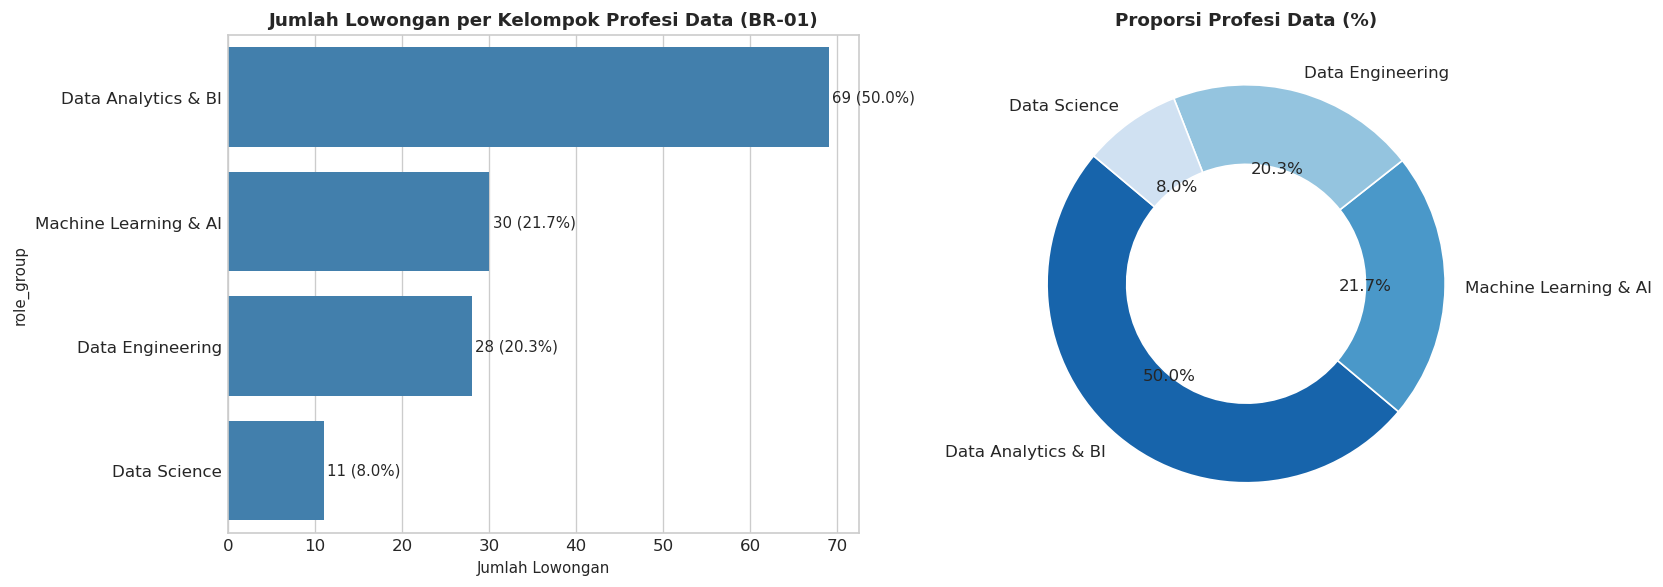

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar Chart
role_counts = df_cleaned_jobs['role_group'].value_counts()
sns.barplot(x=role_counts.values, y=role_counts.index, color='#3182bd', ax=axes[0])
axes[0].set_title("Jumlah Lowongan per Kelompok Profesi Data (BR-01)", fontweight='bold')
axes[0].set_xlabel("Jumlah Lowongan")
for i, v in enumerate(role_counts.values):
    axes[0].text(v + 0.4, i, f"{v} ({v/len(df_cleaned_jobs)*100:.1f}%)", va='center', fontsize=9)

# 2. Donut Chart
axes[1].pie(role_counts.values, labels=role_counts.index, autopct='%1.1f%%', startangle=140, 
            colors=sns.color_palette('Blues_r', len(role_counts)), wedgeprops=dict(width=0.4, edgecolor='w'))
axes[1].set_title("Proporsi Profesi Data (%)", fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "eda_br01_role_composition.png"))
plt.show()

### Sel 13: EDA BR-02 — Top 15 Skill & Tools Paling Banyak Diminta

Menghitung frekuensi lowongan unik yang menyebutkan setiap skill teknis.

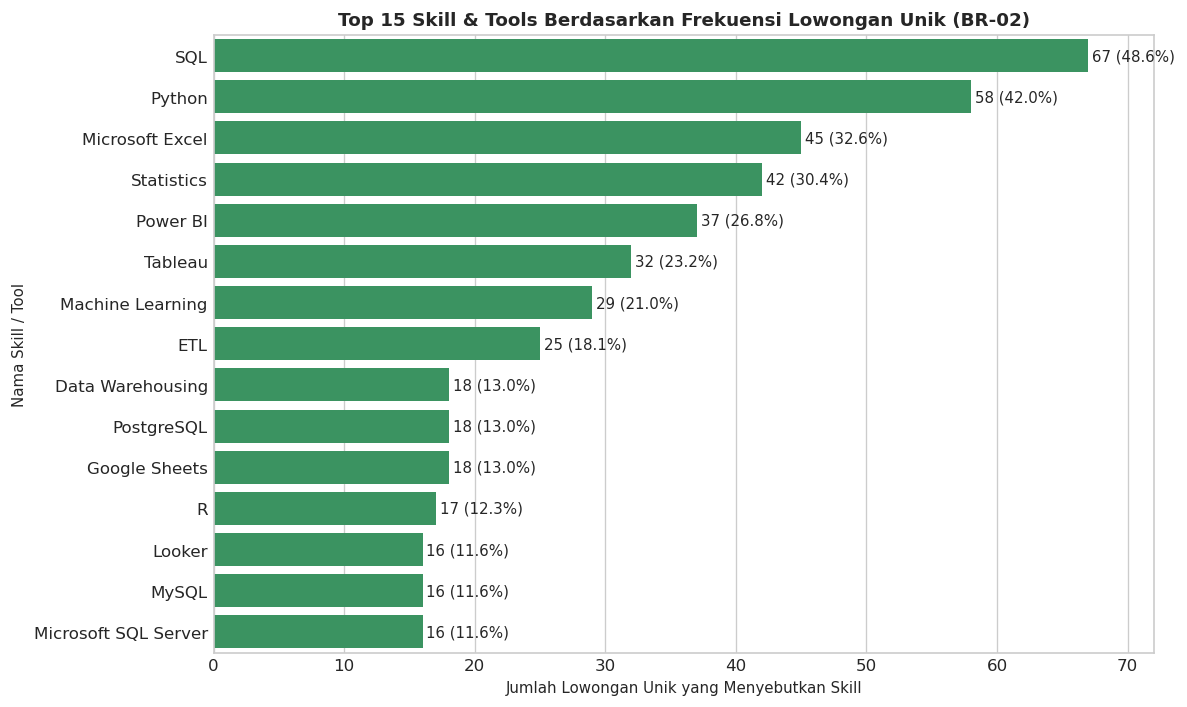

In [13]:
skill_unique_counts = df_job_skills.groupby('skill_name')['job_id'].nunique().sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=skill_unique_counts.values, y=skill_unique_counts.index, color='#2ca25f')
plt.title("Top 15 Skill & Tools Berdasarkan Frekuensi Lowongan Unik (BR-02)", fontweight='bold')
plt.xlabel("Jumlah Lowongan Unik yang Menyebutkan Skill")
plt.ylabel("Nama Skill / Tool")

total_jobs = len(df_cleaned_jobs)
for i, count in enumerate(skill_unique_counts.values):
    pct = (count / total_jobs) * 100
    plt.text(count + 0.3, i, f"{count} ({pct:.1f}%)", va='center', fontsize=9)

plt.xlim(0, max(skill_unique_counts.values) + 5)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "eda_br02_top_skills.png"))
plt.show()

### Sel 14: EDA BR-03 — Distribusi Tingkat Pengalaman Kerja (`experience_level`)

Menganalisis sebaran tingkat pengalaman kategorikal dan distribusinya per kelompok profesi data.

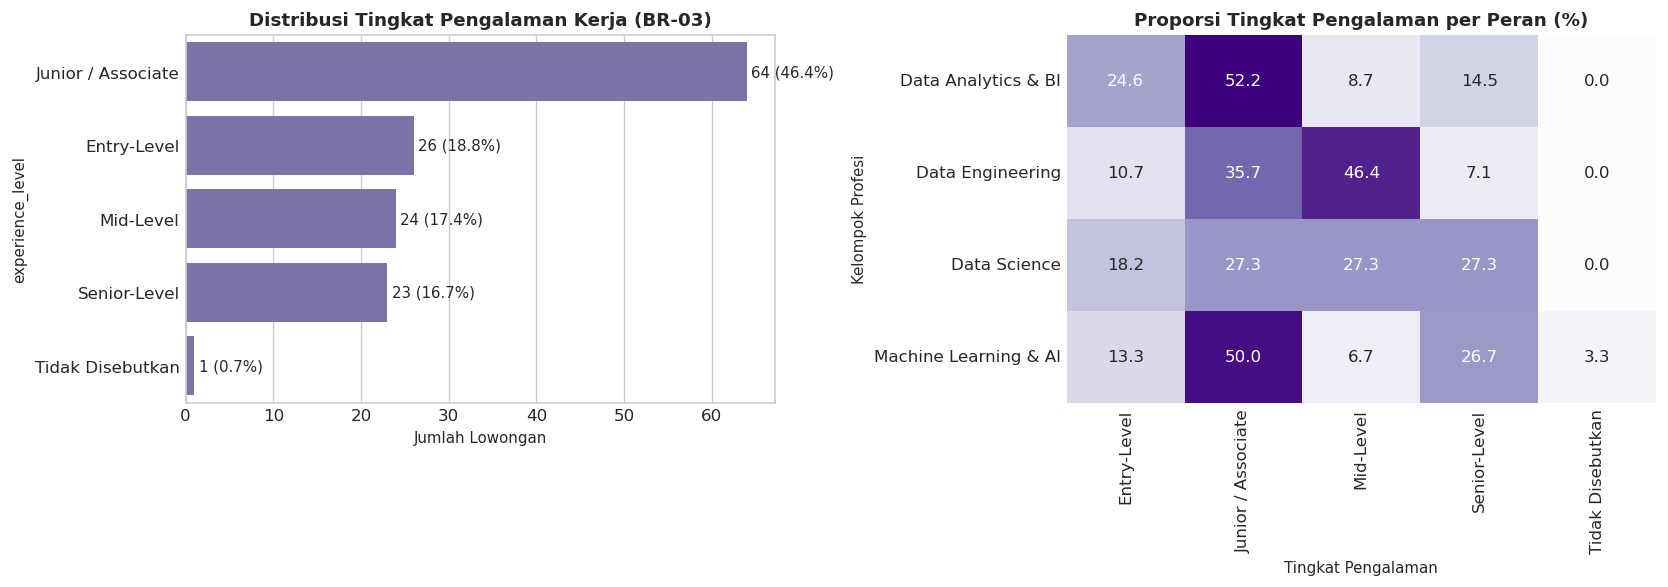

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribusi Keseluruhan Kategori Pengalaman
exp_counts = df_cleaned_jobs['experience_level'].value_counts()
sns.barplot(x=exp_counts.values, y=exp_counts.index, color='#756bb1', ax=axes[0])
axes[0].set_title("Distribusi Tingkat Pengalaman Kerja (BR-03)", fontweight='bold')
axes[0].set_xlabel("Jumlah Lowongan")
for i, count in enumerate(exp_counts.values):
    pct = (count / len(df_cleaned_jobs)) * 100
    axes[0].text(count + 0.5, i, f"{count} ({pct:.1f}%)", va='center', fontsize=9)

# 2. Matriks Silang Peran vs Tingkat Pengalaman
cross_exp = pd.crosstab(df_cleaned_jobs['role_group'], df_cleaned_jobs['experience_level'], normalize='index') * 100
sns.heatmap(cross_exp, annot=True, fmt='.1f', cmap='Purples', cbar=False, ax=axes[1])
axes[1].set_title("Proporsi Tingkat Pengalaman per Peran (%)", fontweight='bold')
axes[1].set_xlabel("Tingkat Pengalaman")
axes[1].set_ylabel("Kelompok Profesi")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "eda_br03_experience_entry_level.png"))
plt.show()

### Sel 15: EDA BR-04 — Persyaratan Kualifikasi Pendidikan Formal

Menganalisis jenjang pendidikan formal minimum yang disyaratkan oleh perusahaan pemberi kerja.

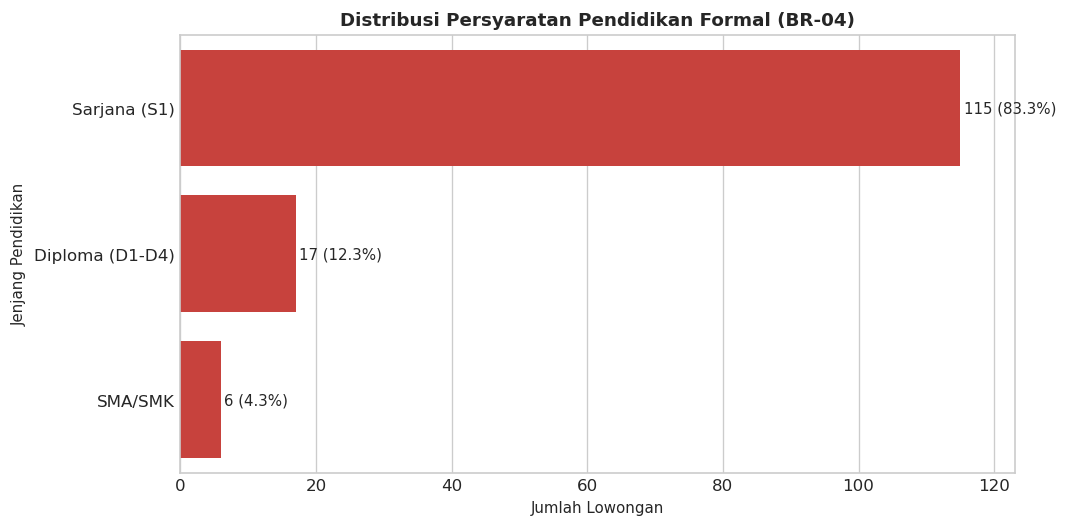

In [15]:
edu_counts = df_cleaned_jobs['education_requirement'].value_counts()

plt.figure(figsize=(9, 4.5))
sns.barplot(x=edu_counts.values, y=edu_counts.index, color='#de2d26')
plt.title("Distribusi Persyaratan Pendidikan Formal (BR-04)", fontweight='bold')
plt.xlabel("Jumlah Lowongan")
plt.ylabel("Jenjang Pendidikan")

for i, count in enumerate(edu_counts.values):
    pct = (count / len(df_cleaned_jobs)) * 100
    plt.text(count + 0.5, i, f"{count} ({pct:.1f}%)", va='center', fontsize=9)

plt.xlim(0, max(edu_counts.values) + 8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "eda_br04_education_requirement.png"))
plt.show()

### Sel 16: EDA BR-05 — Distribusi Gaji per Profesi Data

Menganalisis rentang dan nilai median kompensasi bulanan (Juta Rupiah) per kelompok profesi.

Ringkasan Statistik Gaji Bulanan (Juta Rupiah):
                       count  min  median  mean   max
role_group                                           
Data Analytics & BI       47  0.8     5.2   5.6  17.5
Data Engineering          20  2.8     7.1   7.6  12.5
Data Science               6  1.0     6.2   5.3   9.0
Machine Learning & AI     25  2.0     8.0   9.2  30.0


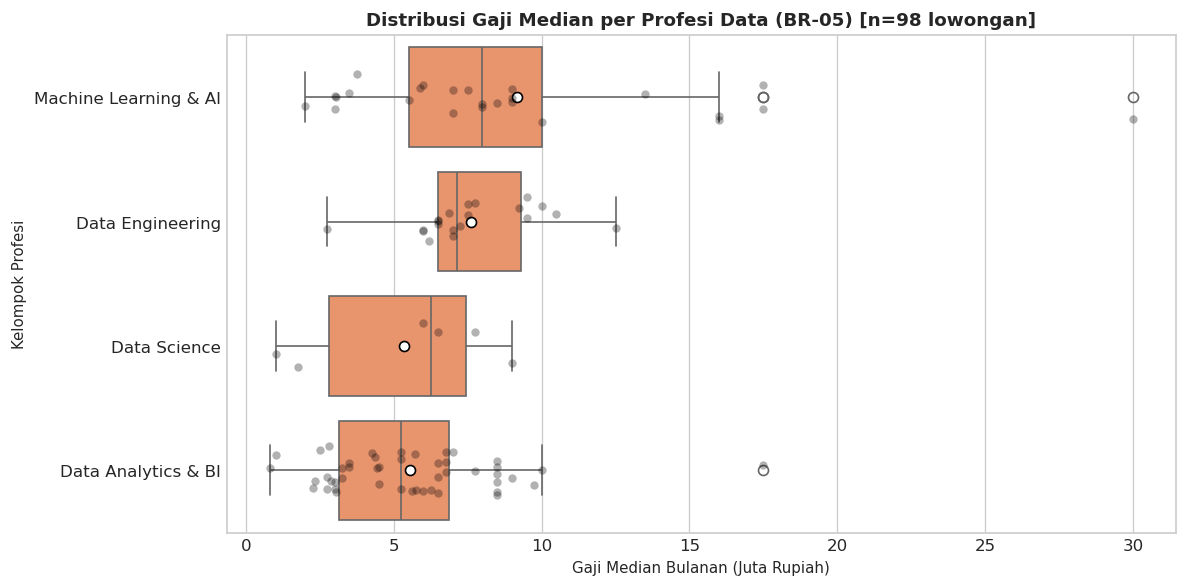

In [16]:
df_salary = df_cleaned_jobs.dropna(subset=['salary_median']).copy()
df_salary['salary_median_mio'] = df_salary['salary_median'] / 1_000_000

plt.figure(figsize=(10, 5))
order = df_salary.groupby('role_group')['salary_median_mio'].median().sort_values(ascending=False).index

sns.boxplot(x='salary_median_mio', y='role_group', data=df_salary, order=order, color='#fc8d59', showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"})
sns.stripplot(x='salary_median_mio', y='role_group', data=df_salary, order=order, color='black', alpha=0.3, jitter=0.2)

plt.title(f"Distribusi Gaji Median per Profesi Data (BR-05) [n={len(df_salary)} lowongan]", fontweight='bold')
plt.xlabel("Gaji Median Bulanan (Juta Rupiah)")
plt.ylabel("Kelompok Profesi")

sal_stats = df_salary.groupby('role_group')['salary_median_mio'].agg(['count', 'min', 'median', 'mean', 'max']).round(1)
print("Ringkasan Statistik Gaji Bulanan (Juta Rupiah):")
print(sal_stats)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "eda_br05_salary_distribution.png"))
plt.show()

### Sel 17: EDA BR-06 — Distribusi Geografis dan Fleksibilitas Mode Kerja

Menganalisis sebaran kota penempatan utama dan proporsi mode kerja (*On-site*, *Hybrid*, *Remote*).

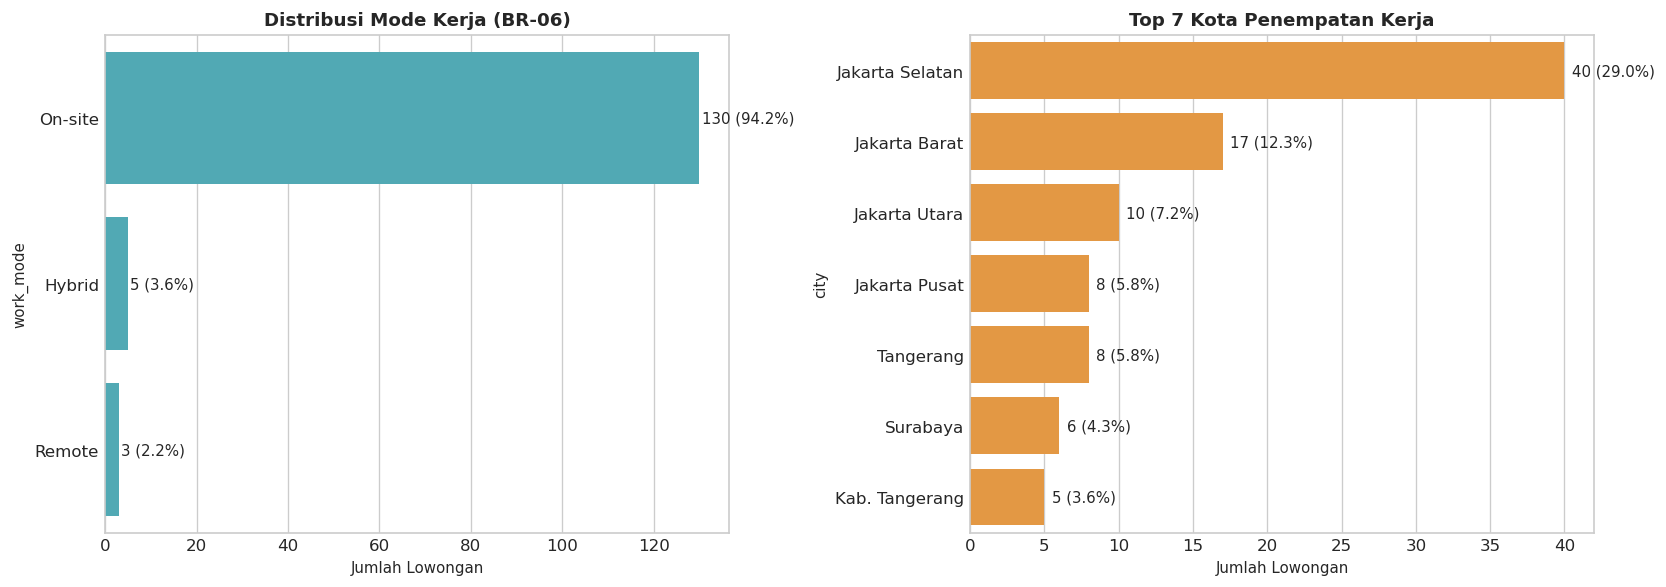

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Mode Kerja
wm_counts = df_cleaned_jobs['work_mode'].value_counts()
sns.barplot(x=wm_counts.values, y=wm_counts.index, color='#41b6c4', ax=axes[0])
axes[0].set_title("Distribusi Mode Kerja (BR-06)", fontweight='bold')
axes[0].set_xlabel("Jumlah Lowongan")
for i, count in enumerate(wm_counts.values):
    pct = (count / len(df_cleaned_jobs)) * 100
    axes[0].text(count + 0.5, i, f"{count} ({pct:.1f}%)", va='center', fontsize=9)

# 2. Top 7 Kota
top_cities = df_cleaned_jobs['city'].value_counts().head(7)
sns.barplot(x=top_cities.values, y=top_cities.index, color='#fe9929', ax=axes[1])
axes[1].set_title("Top 7 Kota Penempatan Kerja", fontweight='bold')
axes[1].set_xlabel("Jumlah Lowongan")
for i, count in enumerate(top_cities.values):
    pct = (count / len(df_cleaned_jobs)) * 100
    axes[1].text(count + 0.5, i, f"{count} ({pct:.1f}%)", va='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "eda_br06_geography_work_mode.png"))
plt.show()

### Sel 18: Analisis Transparansi Atribut & Nilai Tidak Disebutkan (*Transparency Profile*)

Menganalisis proporsi kelengkapan informasi lowongan kerja pada 4 dimensi kunci: Gaji, Pendidikan, Pengalaman, dan Lokasi. Membuktikan apakah nilai yang tidak disebutkan merefleksikan karakteristik perekrutan berbasis kompetensi (*skills-first*) atau batasan format pencatatan portal.

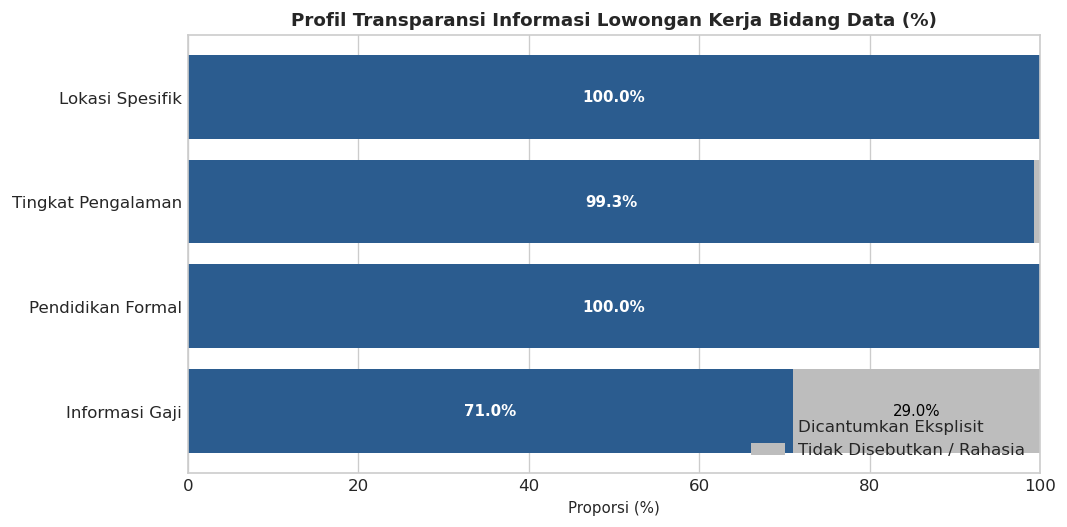

Ringkasan Profil Transparansi:
           Atribut  Tingkat Keterisian (%)  Tidak Disebutkan (%)
    Informasi Gaji               71.014493             28.985507
 Pendidikan Formal              100.000000              0.000000
Tingkat Pengalaman               99.275362              0.724638
   Lokasi Spesifik              100.000000              0.000000


In [18]:
# Hitung persentase keterisian vs Tidak Disebutkan
transparency_data = {
    'Informasi Gaji': (df_cleaned_jobs['salary_median'].notnull().mean() * 100),
    'Pendidikan Formal': ((df_cleaned_jobs['education_requirement'] != 'Tidak Disebutkan').mean() * 100),
    'Tingkat Pengalaman': ((df_cleaned_jobs['experience_level'] != 'Tidak Disebutkan').mean() * 100),
    'Lokasi Spesifik': ((df_cleaned_jobs['city'] != 'Lainnya / Tidak Disebutkan').mean() * 100)
}

df_trans = pd.DataFrame(list(transparency_data.items()), columns=['Atribut', 'Tingkat Keterisian (%)'])
df_trans['Tidak Disebutkan (%)'] = 100.0 - df_trans['Tingkat Keterisian (%)']

plt.figure(figsize=(9, 4.5))
bar1 = plt.barh(df_trans['Atribut'], df_trans['Tingkat Keterisian (%)'], color='#2b5c8f', label='Dicantumkan Eksplisit')
bar2 = plt.barh(df_trans['Atribut'], df_trans['Tidak Disebutkan (%)'], left=df_trans['Tingkat Keterisian (%)'], color='#bdbdbd', label='Tidak Disebutkan / Rahasia')

plt.title("Profil Transparansi Informasi Lowongan Kerja Bidang Data (%)", fontweight='bold')
plt.xlabel("Proporsi (%)")
plt.xlim(0, 100)
plt.legend(loc='lower right')

for i, row in df_trans.iterrows():
    plt.text(row['Tingkat Keterisian (%)'] / 2, i, f"{row['Tingkat Keterisian (%)']:.1f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=9)
    if row['Tidak Disebutkan (%)'] > 5:
        plt.text(row['Tingkat Keterisian (%)'] + row['Tidak Disebutkan (%)'] / 2, i, f"{row['Tidak Disebutkan (%)']:.1f}%", va='center', ha='center', color='black', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "eda_attribute_transparency_profile.png"))
plt.show()

print("Ringkasan Profil Transparansi:")
print(df_trans.to_string(index=False))

### Sel 19: Ekspor Dataset Bersih (Processed Layer)

Menyimpan tabel hasil transformasi ke direktori `data/processed/`:
1. `cleaned_jobs_glints.csv`: Tabel utama lowongan kerja terstandarisasi.
2. `job_skills_glints.csv`: Tabel relasi keahlian teknis per lowongan.

In [19]:
cleaned_jobs_path = os.path.join(PROCESSED_DATA_DIR, "cleaned_jobs_glints.csv")
job_skills_path = os.path.join(PROCESSED_DATA_DIR, "job_skills_glints.csv")

df_cleaned_jobs.to_csv(cleaned_jobs_path, index=False, encoding="utf-8")
df_job_skills.to_csv(job_skills_path, index=False, encoding="utf-8")

print("Dataset bersih berhasil diekspor:")
print(f"1. Cleaned Jobs : {cleaned_jobs_path} ({len(df_cleaned_jobs)} baris)")
print(f"2. Job Skills   : {job_skills_path} ({len(df_job_skills)} relasi)")

Dataset bersih berhasil diekspor:
1. Cleaned Jobs : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed\cleaned_jobs_glints.csv (138 baris)
2. Job Skills   : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed\job_skills_glints.csv (662 relasi)
